# AI Applications & Mini Project 1 — Predictive maintenance

**Digital Foundation for Chemical Engineers**  \n
Duration: 60 minutes

## Today’s goal
Understand how sensor data can support maintenance decisions, explore a pump-data CSV, and build a transparent first-pass maintenance flag. Predictive maintenance supports—not replaces—inspection, maintenance expertise, and safety procedures.

## 1. From reactive to predictive maintenance (10 min)

- Reactive: repair after failure.
- Preventive: service on a fixed schedule.
- Predictive: use condition, operating, and history data to prioritise maintenance.

AI may find patterns across variables or predict future condition. Before using a model, we need trustworthy data, a defined target, and safe human decision-making. An algorithmic score is not a maintenance instruction.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pump_data = pd.read_csv('data/equipment_sensor_120.csv')
pump_data['timestamp'] = pd.to_datetime(pump_data['timestamp'])
pump_data.head()

,timestamp,pump_id,vibration_mm_s,bearing_temperature_c,motor_current_a,running_hours
0,2026-02-02 08:00:00,P-1,2.10,57.0,18.00,1000
1,2026-02-02 09:00:00,P-2,2.18,57.5,18.23,1006
2,2026-02-02 10:00:00,P-3,2.26,57.9,18.46,1012
3,2026-02-02 11:00:00,P-1,2.34,58.4,18.69,1018
4,2026-02-02 12:00:00,P-2,2.42,58.8,18.92,1024


## 2. Inspect before making claims (10 min)

The CSV contains pump identity, vibration, bearing temperature, motor current, and running hours. Ask: What does each measurement mean? How often was it sampled? Is the sensor calibrated? Which inspection findings or failures would be needed to train a real model?

In [2]:
pump_data.info()
display(pump_data.describe())
print('Missing values:')
print(pump_data.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   timestamp              120 non-null    datetime64[us]
 1   pump_id                120 non-null    str           
 2   vibration_mm_s         120 non-null    float64       
 3   bearing_temperature_c  120 non-null    float64       
 4   motor_current_a        120 non-null    float64       
 5   running_hours          120 non-null    int64         
dtypes: datetime64[us](1), float64(3), int64(1), str(1)
memory usage: 5.8 KB


,timestamp,vibration_mm_s,bearing_temperature_c,motor_current_a,running_hours
count,120,120.000000,120.000000,120.000000,120.000000
mean,2026-02-04 19:30:00,2.570000,60.393333,18.902750,1357.000000
min,2026-02-02 08:00:00,2.100000,57.000000,18.000000,1000.000000
25%,2026-02-03 13:45:00,2.320000,58.400000,18.460000,1178.500000
50%,2026-02-04 19:30:00,2.540000,60.100000,18.920000,1357.000000
75%,2026-02-06 01:15:00,2.820000,62.000000,19.380000,1535.500000
max,2026-02-07 07:00:00,3.800000,67.300000,19.840000,1714.000000
std,NaN,0.343144,2.344016,0.599442,208.710326


Missing values:
timestamp                0
pump_id                  0
vibration_mm_s           0
bearing_temperature_c    0
motor_current_a          0
running_hours            0
dtype: int64


In [7]:
max_vibration=pump_data[pump_data['vibration_mm_s']=='3.800000']
display(max_vibration)

,timestamp,pump_id,vibration_mm_s,bearing_temperature_c,motor_current_a,running_hours


**Try it (4 min):** Identify the maximum vibration and the pump on which it occurred.

**Challenge:** Group by pump_id and compare average vibration and bearing temperature.

## 3. Visual inspection of condition trends (12 min)

A trend chart is often the first useful maintenance tool. It can reveal drift, spikes, or changes after maintenance. A visual pattern alone does not establish a fault cause.

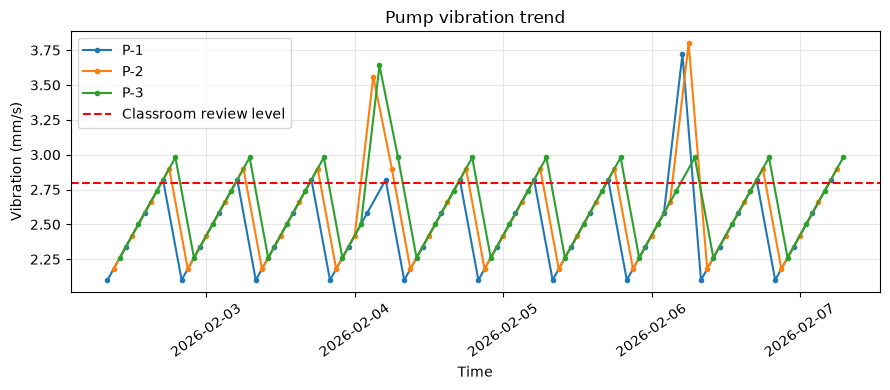

In [4]:
plt.figure(figsize=(9, 4))
for pump_id, group in pump_data.groupby('pump_id'):
    plt.plot(group['timestamp'], group['vibration_mm_s'], marker='.', label=pump_id)
plt.axhline(2.8, color='red', linestyle='--', label='Classroom review level')
plt.title('Pump vibration trend')
plt.xlabel('Time')
plt.ylabel('Vibration (mm/s)')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

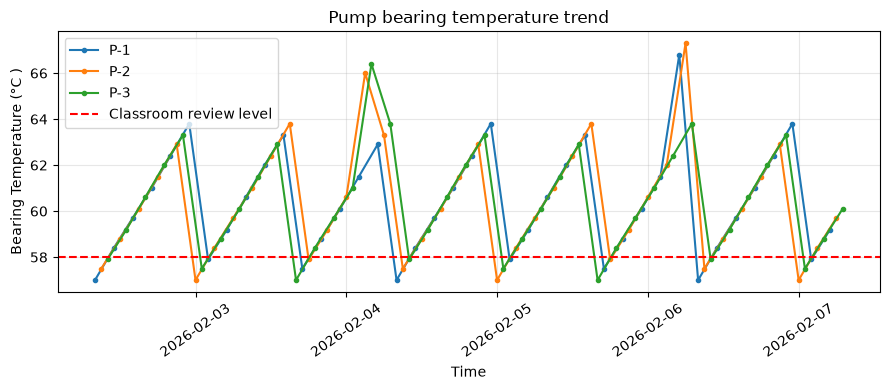

In [10]:
plt.figure(figsize=(9, 4))
for pump_id, group in pump_data.groupby('pump_id'):
    plt.plot(group['timestamp'], group['bearing_temperature_c'], marker='.', label=pump_id)
plt.axhline(58, color='red', linestyle='--', label='Classroom review level')
plt.title('Pump bearing temperature trend')
plt.xlabel('Time')
plt.ylabel('Bearing Temperature (°C )')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

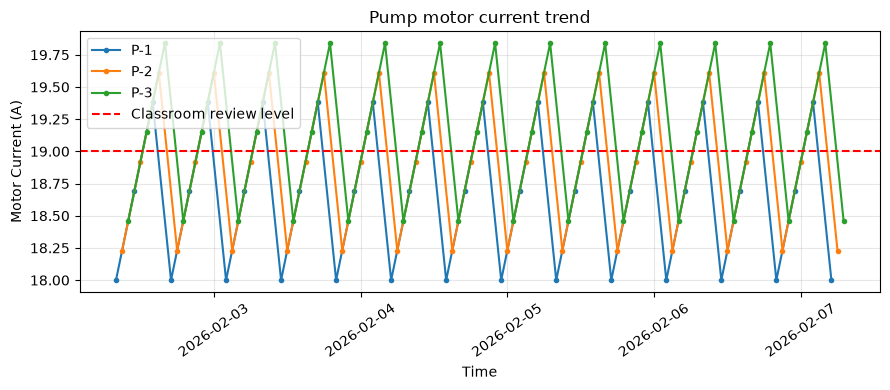

In [12]:
plt.figure(figsize=(9, 4))
for pump_id, group in pump_data.groupby('pump_id'):
    plt.plot(group['timestamp'], group['motor_current_a'], marker='.', label=pump_id)
plt.axhline(19, color='red', linestyle='--', label='Classroom review level')
plt.title('Pump motor current trend')
plt.xlabel('Time')
plt.ylabel('Motor Current (A)')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## 4. Transparent first-pass flag (15 min)

This is a rule-based screening tool, not AI. It helps show what a later ML model would need to improve on. The review levels are classroom examples only and must never be used as real operating limits.

In [13]:
vibration_review_mm_s = 2.8
bearing_review_c = 65
review_readings = pump_data[(pump_data['vibration_mm_s'] >= vibration_review_mm_s) |
                            (pump_data['bearing_temperature_c'] >= bearing_review_c)].copy()
display(review_readings)
print('Readings requiring engineering review:', len(review_readings))

,timestamp,pump_id,vibration_mm_s,bearing_temperature_c,motor_current_a,running_hours
9,2026-02-02 17:00:00,P-1,2.82,61.0,18.00,1054
10,2026-02-02 18:00:00,P-2,2.90,61.5,18.23,1060
11,2026-02-02 19:00:00,P-3,2.98,62.0,18.46,1066
21,2026-02-03 05:00:00,P-1,2.82,59.2,18.69,1126
22,2026-02-03 06:00:00,P-2,2.90,59.7,18.92,1132
23,2026-02-03 07:00:00,P-3,2.98,60.1,19.15,1138
33,2026-02-03 17:00:00,P-1,2.82,57.5,19.38,1198
34,2026-02-03 18:00:00,P-2,2.90,57.9,19.61,1204
35,2026-02-03 19:00:00,P-3,2.98,58.4,19.84,1210
43,2026-02-04 03:00:00,P-2,3.56,66.0,19.61,1258


Readings requiring engineering review: 32


## Pair task (9 min)
Write a two-sentence maintenance note based on the flagged rows. Include the observation and evidence you would seek next.

**Challenge:** Add a review_reason column that distinguishes vibration-only, temperature-only, and both-condition flags.

## Exit check
You can explain the predictive-maintenance workflow and separate a transparent screening rule from an AI prediction. Next: AI-supported quality control.